In [17]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


/home/jpalmo/.conda/envs/tf/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


n = 1901, slope = 0.83, R^2 = 0.68
log-log n = 1887, slope = 0.89, R^2 = 0.85


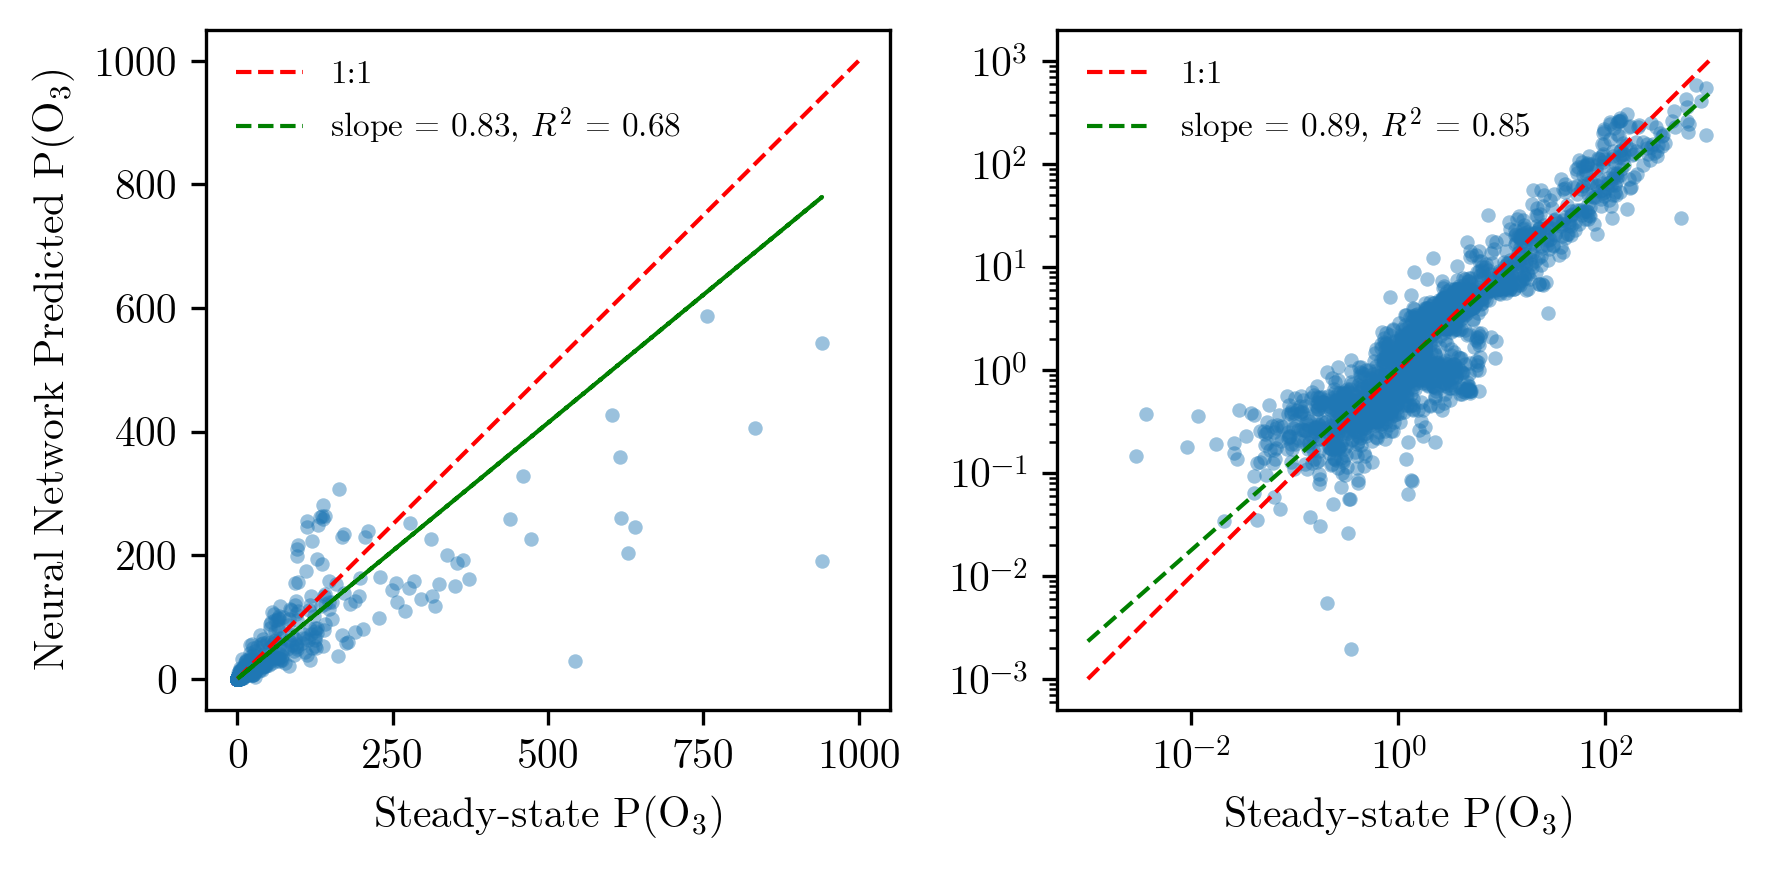

In [18]:
%matplotlib inline

import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import TheilSenRegressor
from sklearn.metrics import r2_score
from tensorflow import keras

MODEL_DIR = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data")
DATA = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/training_data_po3.csv")
FEATURES = ["smoke_age", "normalized_distance_to_center", "CH2O", "NO2"]
TEST_FIRE = 1.0

data = pd.read_csv(DATA)
data = data[FEATURES + ["pO3", "fire_id"]].dropna()
data = data[data["pO3"] > 0]
test = data[data["fire_id"] == TEST_FIRE]
with (MODEL_DIR / "po3_scaler.pkl").open("rb") as handle:
    scaler = pickle.load(handle)
model = keras.models.load_model(MODEL_DIR / "po3_nn_model.keras")
predicted = np.expm1(model.predict(scaler.transform(test[FEATURES]), verbose=0).ravel())
observed = test["pO3"].to_numpy()

def theil_sen_fit(x, y):
    fit = TheilSenRegressor(random_state=0).fit(np.asarray(x).reshape(-1, 1), y)
    return float(fit.coef_[0]), float(fit.intercept_)

slope, intercept = theil_sen_fit(observed, predicted)
r2 = r2_score(observed, predicted)
positive = (observed > 0) & (predicted > 0)
log_obs = np.log(observed[positive])
log_pred = np.log(predicted[positive])
log_slope, log_intercept = theil_sen_fit(log_obs, log_pred)
log_r2 = r2_score(log_obs, log_pred)
print(f"n = {len(test)}, slope = {slope:.2f}, R^2 = {r2:.2f}")
print(f"log-log n = {positive.sum()}, slope = {log_slope:.2f}, R^2 = {log_r2:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=300)
for ax in axes:
    ax.scatter(observed, predicted, s=12, alpha=0.45, linewidths=0)
    ax.plot([1e-3, 1000], [1e-3, 1000], "r--", lw=1, label="1:1")
    ax.set_xlabel(r"Steady-state P(O$_3$)")
axes[0].plot(observed, slope * observed + intercept, "g--", lw=1, label=f"slope = {slope:.2f}, $R^2$ = {r2:.2f}")
axes[0].set_ylabel(r"Neural Network Predicted P(O$_3$)")
axes[0].legend(fontsize=8, frameon=False)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
x_line = np.array([1e-3, 1000.0])
axes[1].plot(
    x_line,
    np.exp(log_intercept) * x_line**log_slope,
    "g--",
    lw=1,
    label=f"slope = {log_slope:.2f}, $R^2$ = {log_r2:.2f}",
)
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs09.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs09.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
